In [1]:
import zipfile
import os

# Find the uploaded ZIP file
zip_files = [f for f in os.listdir("/content") if f.endswith(".zip")]

print("Uploaded ZIP files:", zip_files)

# Extract dataset
if zip_files:
    zip_path = os.path.join("/content", zip_files[0])

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content/resume_dataset")

    print("Dataset extracted successfully!")
else:
    print("Please upload your Kaggle ZIP file first.")

Uploaded ZIP files: []
Please upload your Kaggle ZIP file first.


In [3]:
import os

zip_files = [f for f in os.listdir("/content") if f.endswith(".zip")]
print("Uploaded ZIP files:", zip_files)

Uploaded ZIP files: ['archive (5).zip']


In [5]:
import zipfile
import os

zip_path = "/content/archive (5).zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/resume_dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [7]:
import os

for root, dirs, files in os.walk("/content/resume_dataset"):
    for file in files:
        print(os.path.join(root, file))

/content/resume_dataset/data/data/AVIATION/17983430.pdf
/content/resume_dataset/data/data/AVIATION/28383893.pdf
/content/resume_dataset/data/data/AVIATION/42641525.pdf
/content/resume_dataset/data/data/AVIATION/10176815.pdf
/content/resume_dataset/data/data/AVIATION/54232810.pdf
/content/resume_dataset/data/data/AVIATION/17686472.pdf
/content/resume_dataset/data/data/AVIATION/12504278.pdf
/content/resume_dataset/data/data/AVIATION/77626587.pdf
/content/resume_dataset/data/data/AVIATION/26888302.pdf
/content/resume_dataset/data/data/AVIATION/30148777.pdf
/content/resume_dataset/data/data/AVIATION/31605080.pdf
/content/resume_dataset/data/data/AVIATION/11137306.pdf
/content/resume_dataset/data/data/AVIATION/17483843.pdf
/content/resume_dataset/data/data/AVIATION/43408471.pdf
/content/resume_dataset/data/data/AVIATION/28020046.pdf
/content/resume_dataset/data/data/AVIATION/16833515.pdf
/content/resume_dataset/data/data/AVIATION/23985183.pdf
/content/resume_dataset/data/data/AVIATION/91431

In [9]:
import os

dataset_path = "/content/resume_dataset/data/data"

for category in sorted(os.listdir(dataset_path)):
    category_path = os.path.join(dataset_path, category)

    if os.path.isdir(category_path):
        pdf_files = [
            f for f in os.listdir(category_path)
            if f.lower().endswith(".pdf")
        ]

        print(f"{category}: {len(pdf_files)} resumes")

ACCOUNTANT: 118 resumes
ADVOCATE: 118 resumes
AGRICULTURE: 63 resumes
APPAREL: 97 resumes
ARTS: 103 resumes
AUTOMOBILE: 36 resumes
AVIATION: 117 resumes
BANKING: 115 resumes
BPO: 22 resumes
BUSINESS-DEVELOPMENT: 120 resumes
CHEF: 118 resumes
CONSTRUCTION: 112 resumes
CONSULTANT: 115 resumes
DESIGNER: 107 resumes
DIGITAL-MEDIA: 96 resumes
ENGINEERING: 118 resumes
FINANCE: 118 resumes
FITNESS: 117 resumes
HEALTHCARE: 115 resumes
HR: 110 resumes
INFORMATION-TECHNOLOGY: 120 resumes
PUBLIC-RELATIONS: 111 resumes
SALES: 116 resumes
TEACHER: 102 resumes


In [11]:
!pip install pypdf scikit-learn pandas matplotlib seaborn

In [13]:
import os
import pandas as pd
from pypdf import PdfReader

dataset_path = "/content/resume_dataset/data/data"

resumes = []

for category in sorted(os.listdir(dataset_path)):
    category_path = os.path.join(dataset_path, category)

    if os.path.isdir(category_path):
        for filename in os.listdir(category_path):
            if filename.lower().endswith(".pdf"):
                pdf_path = os.path.join(category_path, filename)

                try:
                    reader = PdfReader(pdf_path)
                    text = ""

                    for page in reader.pages:
                        text += page.extract_text() or ""

                    resumes.append({
                        "candidate_id": filename.replace(".pdf", ""),
                        "category": category,
                        "resume_text": text
                    })

                except Exception as e:
                    print(f"Could not read {filename}: {e}")

df = pd.DataFrame(resumes)

print("Total resumes processed:", len(df))
print("Total columns:", len(df.columns))
print("\nFirst 5 records:")
print(df[["candidate_id", "category"]].head())

Total resumes processed: 2484
Total columns: 3

First 5 records:
  candidate_id    category
0     14449423  ACCOUNTANT
1     12338274  ACCOUNTANT
2     24817041  ACCOUNTANT
3     14055988  ACCOUNTANT
4     25067742  ACCOUNTANT


In [15]:
# Check for missing or empty resume text
df["resume_length"] = df["resume_text"].fillna("").str.len()

print("Total resumes:", len(df))
print("Empty resumes:", (df["resume_length"] == 0).sum())
print("Average resume length:", round(df["resume_length"].mean(), 2))
print("Shortest resume:", df["resume_length"].min())
print("Longest resume:", df["resume_length"].max())

print("\nResume text sample:")
print(df.loc[df["resume_length"].idxmax(), "resume_text"][:500])

Total resumes: 2484
Empty resumes: 1
Average resume length: 6021.34
Shortest resume: 0
Longest resume: 35209

Resume text sample:
BARTENDER
Experience
Bartender
 
, 
05/2018
 
Company Name
 
â€“ 
City
 
, 
State
 
Marketing & Public Relations: 10 years, Maintain proper and adequate set-up of the bar on a daily basis.
Responsible for maintaining stock, preparing and storing of all garnishes, juices and other perishables to ensure product quality.
Attend stand ups prior to each function to obtain all details in order to execute each event flawlessly.
Set up and breakdown all mobile bars per hotel standards.
Greets guests wit


In [17]:
import re
import unicodedata

def clean_resume(text):
    text = str(text)

    # Normalize unusual characters
    text = unicodedata.normalize("NFKC", text)

    # Convert text to lowercase
    text = text.lower()

    # Remove email addresses
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove website links
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove phone numbers
    text = re.sub(r'\b\d{7,}\b', ' ', text)

    # Remove special characters and extra spaces
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

# Apply cleaning
df["cleaned_resume"] = df["resume_text"].fillna("").apply(clean_resume)

# Remove empty resumes
df = df[df["cleaned_resume"].str.len() > 0].copy()

print("Preprocessing completed!")
print("Remaining resumes:", len(df))

print("\nCleaned resume sample:")
print(df["cleaned_resume"].iloc[0][:500])

Preprocessing completed!
Remaining resumes: 2483

Cleaned resume sample:
staff accountant professional profile to advance in professional and personal experiences within finance tax accounting and management to obtain a staff accountant position that will enable me to perform my best using my mathematical numerical accounting and analytical ability for the betterment of the organization highly proactive professional with years of experience in accounting and economics eager to achieve highest standard of accounting operations and greatest quality of work outstanding 


In [19]:
skills_dictionary = {
    "python": ["python"],
    "java": ["java"],
    "machine learning": ["machine learning"],
    "data analysis": ["data analysis", "data analytics"],
    "sql": ["sql", "mysql", "postgresql"],
    "excel": ["excel", "microsoft excel"],
    "power bi": ["power bi"],
    "communication": ["communication", "verbal communication"],
    "project management": ["project management"],
    "leadership": ["leadership", "team leadership"],
    "accounting": ["accounting", "financial accounting"],
    "financial analysis": ["financial analysis"],
    "bookkeeping": ["bookkeeping"],
    "auditing": ["auditing", "audit"],
    "taxation": ["taxation", "tax preparation"],
    "autocad": ["autocad"],
    "engineering": ["engineering"],
    "civil engineering": ["civil engineering"],
    "mechanical engineering": ["mechanical engineering"],
    "electrical engineering": ["electrical engineering"],
    "problem solving": ["problem solving", "problem-solving"],
    "customer service": ["customer service"],
    "sales": ["sales", "sales management"],
    "marketing": ["marketing", "digital marketing"],
    "human resources": ["human resources", "recruitment"],
    "teaching": ["teaching", "lesson planning"],
    "research": ["research", "data collection"],
    "html": ["html"],
    "css": ["css"],
    "javascript": ["javascript"],
    "database management": ["database management"],
    "networking": ["networking", "computer networks"],
    "cybersecurity": ["cybersecurity", "information security"],
    "cloud computing": ["cloud computing", "aws", "azure"],
    "communication skills": ["communication skills"]
}

print("Total skill categories:", len(skills_dictionary))
print("\nAvailable skills:")

for skill in skills_dictionary:
    print("-", skill)

Total skill categories: 35

Available skills:
- python
- java
- machine learning
- data analysis
- sql
- excel
- power bi
- communication
- project management
- leadership
- accounting
- financial analysis
- bookkeeping
- auditing
- taxation
- autocad
- engineering
- civil engineering
- mechanical engineering
- electrical engineering
- problem solving
- customer service
- sales
- marketing
- human resources
- teaching
- research
- html
- css
- javascript
- database management
- networking
- cybersecurity
- cloud computing
- communication skills


In [21]:
def extract_skills(resume_text):
    found_skills = []

    for skill, keywords in skills_dictionary.items():
        for keyword in keywords:
            pattern = r'\b' + re.escape(keyword) + r'\b'

            if re.search(pattern, resume_text):
                found_skills.append(skill)
                break

    return found_skills

# Extract skills from every resume
df["extracted_skills"] = df["cleaned_resume"].apply(extract_skills)

# Count how many resumes contain at least one skill
resumes_with_skills = (df["extracted_skills"].str.len() > 0).sum()

print("Skill extraction completed!")
print("Total resumes:", len(df))
print("Resumes with identified skills:", resumes_with_skills)
print("Resumes without identified skills:", len(df) - resumes_with_skills)

print("\nSample extracted skills:")
for i in range(5):
    print(f"\nCandidate {df.iloc[i]['candidate_id']}:")
    print(df.iloc[i]["extracted_skills"])

Skill extraction completed!
Total resumes: 2483
Resumes with identified skills: 2444
Resumes without identified skills: 39

Sample extracted skills:

Candidate 14449423:
['sql', 'excel', 'communication', 'accounting', 'taxation', 'sales', 'research']

Candidate 12338274:
['accounting', 'auditing', 'taxation', 'sales']

Candidate 24817041:
['excel', 'accounting', 'auditing']

Candidate 14055988:
['communication', 'accounting', 'auditing', 'customer service', 'teaching', 'research', 'communication skills']

Candidate 25067742:
['excel', 'accounting', 'bookkeeping']


In [23]:
from collections import Counter

# Count all extracted skills
all_skills = []

for skills in df["extracted_skills"]:
    all_skills.extend(skills)

skill_counts = Counter(all_skills)

# Create a table of the 15 most common skills
top_skills = pd.DataFrame(
    skill_counts.most_common(15),
    columns=["Skill", "Number of Resumes"]
)

print("TOP 15 MOST COMMON SKILLS")
display(top_skills)

TOP 15 MOST COMMON SKILLS


,Skill,Number of Resumes
0,sales,1311
1,communication,1297
2,leadership,1023
3,customer service,976
4,excel,960
5,marketing,870
6,research,787
7,communication skills,617
8,accounting,560
9,project management,557


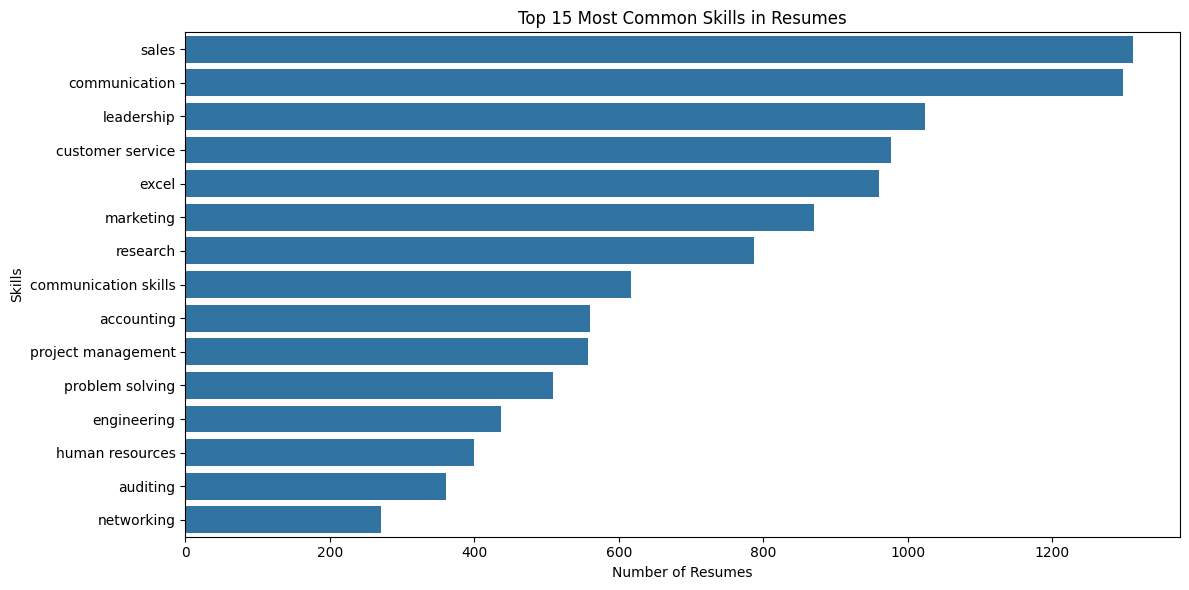

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_skills,
    x="Number of Resumes",
    y="Skill"
)

plt.title("Top 15 Most Common Skills in Resumes")
plt.xlabel("Number of Resumes")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()

In [27]:
job_title = "Junior Data Analyst"

job_description = """
We are looking for a Junior Data Analyst with skills in Python,
SQL, Microsoft Excel, Power BI and data analysis.

The successful candidate should have knowledge of data cleaning,
data visualization, statistical analysis and database management.

Candidates should demonstrate problem-solving abilities,
communication skills, teamwork and attention to detail.

A degree or diploma in Information Technology, Computer Science,
Statistics or a related field is preferred.
"""

required_skills = [
    "python",
    "sql",
    "excel",
    "power bi",
    "data analysis",
    "database management",
    "communication",
    "problem solving",
    "research"
]

print("JOB TITLE:", job_title)
print("\nJOB DESCRIPTION:")
print(job_description)

print("\nREQUIRED SKILLS:")
for skill in required_skills:
    print("-", skill)

JOB TITLE: Junior Data Analyst

JOB DESCRIPTION:

We are looking for a Junior Data Analyst with skills in Python,
SQL, Microsoft Excel, Power BI and data analysis.

The successful candidate should have knowledge of data cleaning,
data visualization, statistical analysis and database management.

Candidates should demonstrate problem-solving abilities,
communication skills, teamwork and attention to detail.

A degree or diploma in Information Technology, Computer Science,
Statistics or a related field is preferred.


REQUIRED SKILLS:
- python
- sql
- excel
- power bi
- data analysis
- database management
- communication
- problem solving
- research


In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Combine the job description and all resumes
documents = [job_description] + df["cleaned_resume"].tolist()

# Convert text into numerical TF-IDF features
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2)
)

tfidf_matrix = vectorizer.fit_transform(documents)

# Compare each resume with the job description
similarity_scores = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:]
).flatten()

# Store similarity scores as percentages
df["similarity_score"] = similarity_scores * 100

print("Resume similarity calculation completed!")
print("Total candidates evaluated:", len(df))
print("Average similarity score:", round(df["similarity_score"].mean(), 2), "%")
print("Highest similarity score:", round(df["similarity_score"].max(), 2), "%")
print("Lowest similarity score:", round(df["similarity_score"].min(), 2), "%")

Resume similarity calculation completed!
Total candidates evaluated: 2483
Average similarity score: 3.43 %
Highest similarity score: 30.99 %
Lowest similarity score: 0.0 %


In [31]:
def calculate_skill_match(candidate_skills):
    matched = [
        skill for skill in required_skills
        if skill in candidate_skills
    ]

    missing = [
        skill for skill in required_skills
        if skill not in candidate_skills
    ]

    match_score = (len(matched) / len(required_skills)) * 100

    return matched, missing, match_score


# Apply skill matching to all candidates
df[["matched_skills", "missing_skills", "skill_match_score"]] = (
    df["extracted_skills"]
    .apply(calculate_skill_match)
    .apply(pd.Series)
)

print("Skill matching completed!")
print("Average skill match score:",
      round(df["skill_match_score"].mean(), 2), "%")

print("\nSample candidate skill matching:")
print("Matched:", df.iloc[0]["matched_skills"])
print("Missing:", df.iloc[0]["missing_skills"])
print("Skill score:", round(df.iloc[0]["skill_match_score"], 2), "%")

Skill matching completed!
Average skill match score: 17.9 %

Sample candidate skill matching:
Matched: ['sql', 'excel', 'communication', 'research']
Missing: ['python', 'power bi', 'data analysis', 'database management', 'problem solving']
Skill score: 44.44 %


In [33]:
# Calculate weighted final score
df["final_score"] = (
    0.60 * df["skill_match_score"] +
    0.40 * df["similarity_score"]
)

# Rank candidates from highest to lowest
df = df.sort_values(
    by="final_score",
    ascending=False
).reset_index(drop=True)

# Assign candidate rankings
df["rank"] = range(1, len(df) + 1)

print("Candidate ranking completed!")

print("\nTOP 10 CANDIDATES")

display(
    df[[
        "rank",
        "candidate_id",
        "category",
        "similarity_score",
        "skill_match_score",
        "final_score",
        "matched_skills",
        "missing_skills"
    ]].head(10)
)

Candidate ranking completed!

TOP 10 CANDIDATES


,rank,candidate_id,category,similarity_score,skill_match_score,final_score,matched_skills,missing_skills
0,1,25397102,BUSINESS-DEVELOPMENT,17.940047,66.666667,47.176019,"[python, sql, excel, communication, problem so...","[power bi, data analysis, database management]"
1,2,18448085,AUTOMOBILE,30.784727,55.555556,45.647224,"[python, sql, excel, data analysis, problem so...","[power bi, database management, communication,..."
2,3,13405733,INFORMATION-TECHNOLOGY,13.062289,66.666667,45.224915,"[python, sql, excel, communication, problem so...","[power bi, data analysis, database management]"
3,4,11957080,INFORMATION-TECHNOLOGY,10.716759,66.666667,44.286704,"[sql, excel, data analysis, communication, pro...","[python, power bi, database management]"
4,5,12011623,ENGINEERING,24.928462,55.555556,43.304718,"[python, sql, data analysis, database manageme...","[excel, power bi, communication, problem solving]"
5,6,95792386,CONSULTANT,7.581403,66.666667,43.032561,"[sql, excel, data analysis, communication, pro...","[python, power bi, database management]"
6,7,12351749,SALES,19.103542,55.555556,40.974750,"[excel, data analysis, communication, problem ...","[python, sql, power bi, database management]"
7,8,24610685,SALES,16.605625,55.555556,39.975583,"[sql, excel, data analysis, database managemen...","[python, power bi, problem solving, research]"
8,9,10265057,INFORMATION-TECHNOLOGY,15.498631,55.555556,39.532786,"[python, sql, excel, communication, research]","[power bi, data analysis, database management,..."
9,10,26801767,INFORMATION-TECHNOLOGY,14.335279,55.555556,39.067445,"[excel, data analysis, database management, co...","[python, sql, power bi, problem solving]"


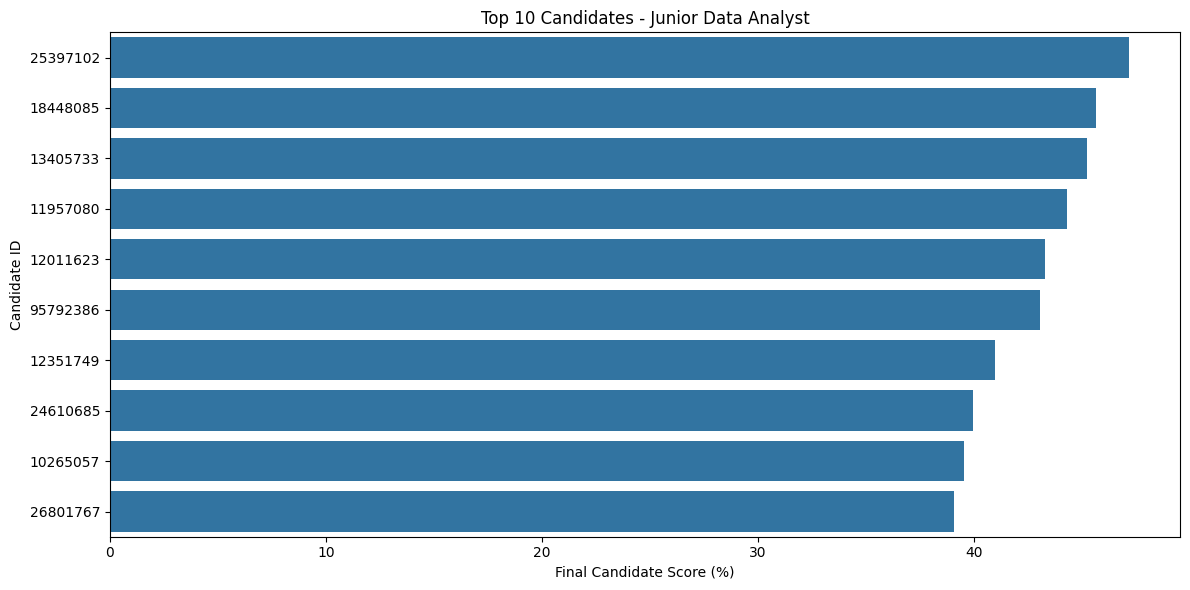

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

top_10 = df.head(10).copy()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x="final_score",
    y="candidate_id"
)

plt.title("Top 10 Candidates - Junior Data Analyst")
plt.xlabel("Final Candidate Score (%)")
plt.ylabel("Candidate ID")
plt.tight_layout()
plt.show()

In [37]:
from collections import Counter

missing_skill_counts = Counter()

for skills in df["missing_skills"]:
    missing_skill_counts.update(skills)

missing_skills_df = pd.DataFrame(
    missing_skill_counts.most_common(),
    columns=["Missing Skill", "Number of Candidates"]
)

print("MOST COMMON MISSING SKILLS")
display(missing_skills_df)

MOST COMMON MISSING SKILLS


,Missing Skill,Number of Candidates
0,power bi,2482
1,python,2443
2,database management,2413
3,data analysis,2339
4,sql,2292
5,problem solving,1974
6,research,1696
7,excel,1523
8,communication,1186


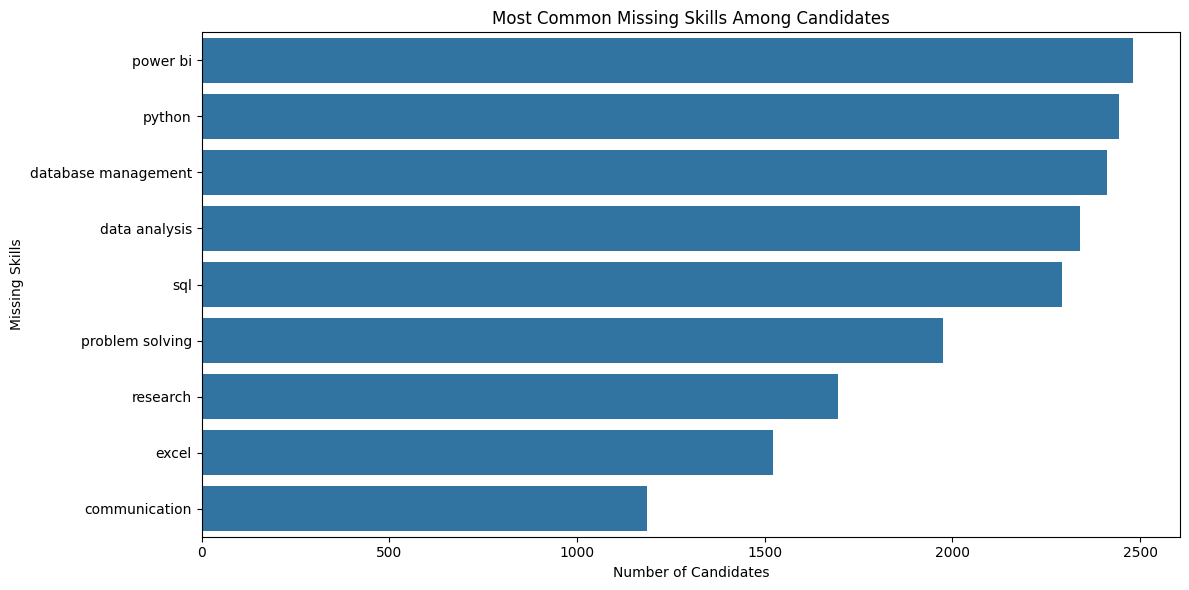

In [39]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_skills_df,
    x="Number of Candidates",
    y="Missing Skill"
)

plt.title("Most Common Missing Skills Among Candidates")
plt.xlabel("Number of Candidates")
plt.ylabel("Missing Skills")
plt.tight_layout()
plt.show()

In [41]:
print("=" * 55)
print("RESUME SCREENING SYSTEM - FINAL REPORT")
print("=" * 55)

print("\nJob Position:", job_title)
print("Total Candidates Evaluated:", len(df))

print("\nTOP CANDIDATE")
best = df.iloc[0]

print("Candidate ID:", best["candidate_id"])
print("Original Resume Category:", best["category"])
print("Similarity Score:", round(best["similarity_score"], 2), "%")
print("Skill Match Score:", round(best["skill_match_score"], 2), "%")
print("Final Score:", round(best["final_score"], 2), "%")

print("\nMatched Skills:")
print(", ".join(best["matched_skills"]))

print("\nMissing Skills:")
print(", ".join(best["missing_skills"]))

print("\nTOP 5 CANDIDATES")
display(
    df[[
        "rank",
        "candidate_id",
        "final_score",
        "matched_skills",
        "missing_skills"
    ]].head(5)
)

print("\nAverage Final Score:",
      round(df["final_score"].mean(), 2), "%")

print("\nSCREENING COMPLETED!")
print("=" * 55)

RESUME SCREENING SYSTEM - FINAL REPORT

Job Position: Junior Data Analyst
Total Candidates Evaluated: 2483

TOP CANDIDATE
Candidate ID: 25397102
Original Resume Category: BUSINESS-DEVELOPMENT
Similarity Score: 17.94 %
Skill Match Score: 66.67 %
Final Score: 47.18 %

Matched Skills:
python, sql, excel, communication, problem solving, research

Missing Skills:
power bi, data analysis, database management

TOP 5 CANDIDATES


,rank,candidate_id,final_score,matched_skills,missing_skills
0,1,25397102,47.176019,"[python, sql, excel, communication, problem so...","[power bi, data analysis, database management]"
1,2,18448085,45.647224,"[python, sql, excel, data analysis, problem so...","[power bi, database management, communication,..."
2,3,13405733,45.224915,"[python, sql, excel, communication, problem so...","[power bi, data analysis, database management]"
3,4,11957080,44.286704,"[sql, excel, data analysis, communication, pro...","[python, power bi, database management]"
4,5,12011623,43.304718,"[python, sql, data analysis, database manageme...","[excel, power bi, communication, problem solving]"



Average Final Score: 12.11 %

SCREENING COMPLETED!


In [43]:
import os

os.makedirs("/content/results", exist_ok=True)

# Save all ranked candidates
df.to_csv(
    "/content/results/candidate_rankings.csv",
    index=False
)

# Save top 10 candidates
df.head(10).to_csv(
    "/content/results/top_10_candidates.csv",
    index=False
)

# Save missing skills analysis
missing_skills_df.to_csv(
    "/content/results/missing_skills_analysis.csv",
    index=False
)

print("Results saved successfully!")

print("\nSaved files:")
print("1. candidate_rankings.csv")
print("2. top_10_candidates.csv")
print("3. missing_skills_analysis.csv")

Results saved successfully!

Saved files:
1. candidate_rankings.csv
2. top_10_candidates.csv
3. missing_skills_analysis.csv


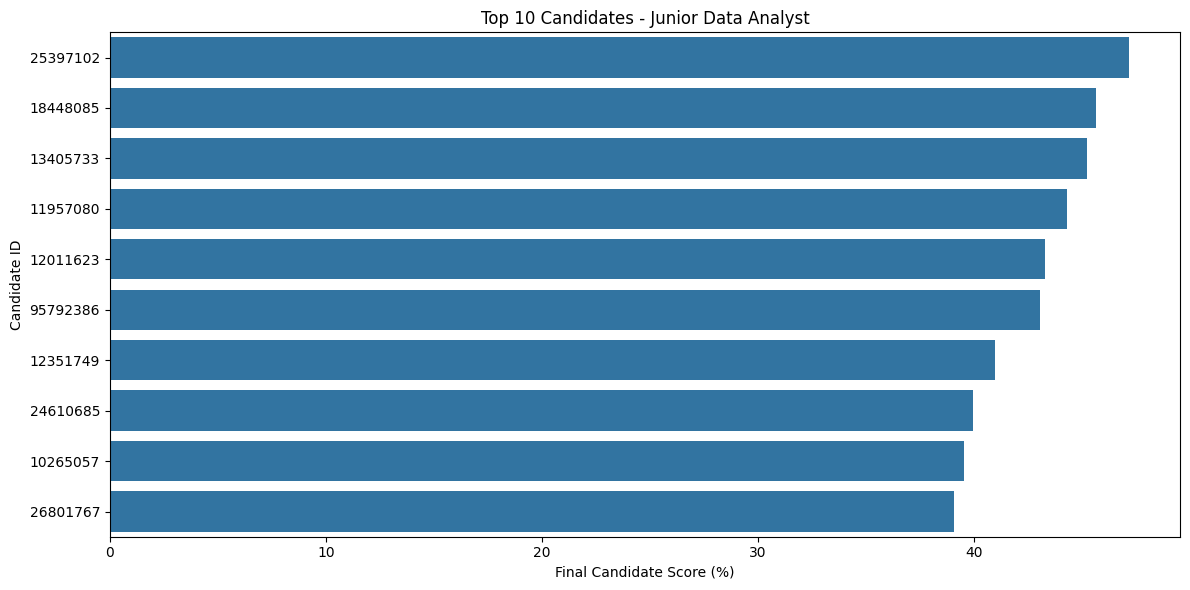

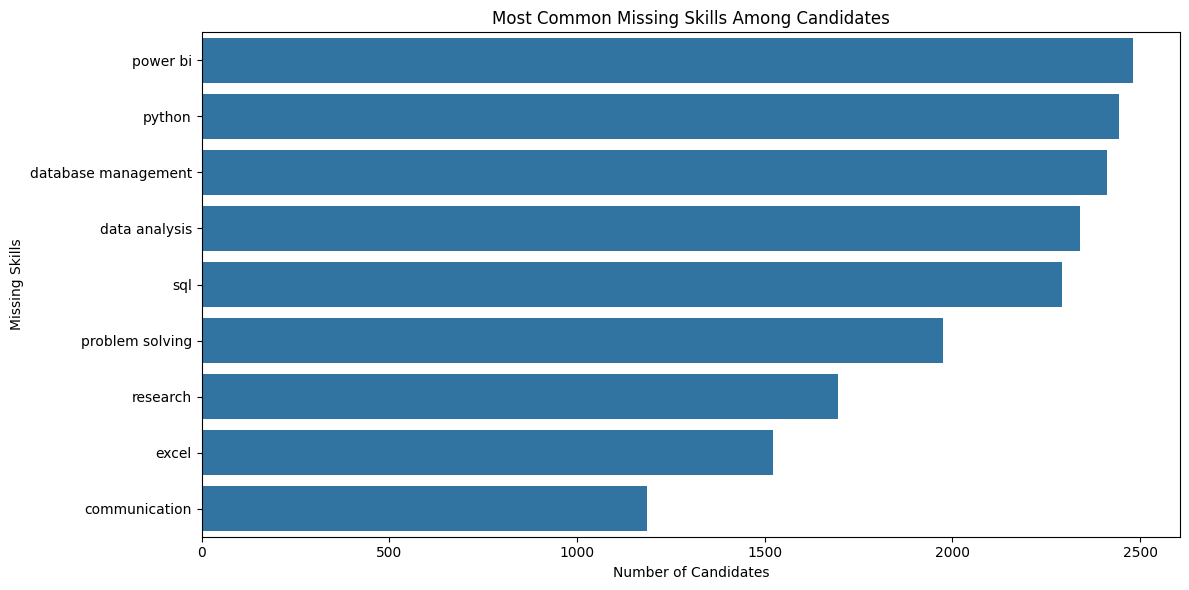

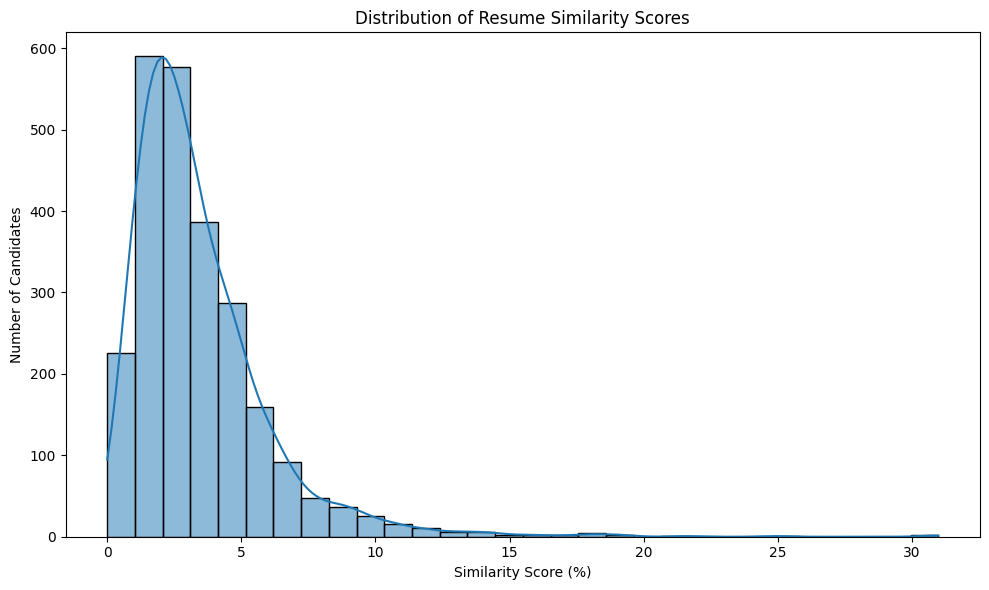

All three charts saved successfully!


In [45]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("/content/results", exist_ok=True)

# Chart 1: Top 10 candidates
plt.figure(figsize=(12, 6))
sns.barplot(data=df.head(10), x="final_score", y="candidate_id")
plt.title("Top 10 Candidates - Junior Data Analyst")
plt.xlabel("Final Candidate Score (%)")
plt.ylabel("Candidate ID")
plt.tight_layout()
plt.savefig("/content/results/top_10_candidates.png", dpi=300)
plt.show()

# Chart 2: Missing skills
plt.figure(figsize=(12, 6))
sns.barplot(
    data=missing_skills_df,
    x="Number of Candidates",
    y="Missing Skill"
)
plt.title("Most Common Missing Skills Among Candidates")
plt.xlabel("Number of Candidates")
plt.ylabel("Missing Skills")
plt.tight_layout()
plt.savefig("/content/results/missing_skills.png", dpi=300)
plt.show()

# Chart 3: Similarity score distribution
plt.figure(figsize=(10, 6))
sns.histplot(df["similarity_score"], bins=30, kde=True)
plt.title("Distribution of Resume Similarity Scores")
plt.xlabel("Similarity Score (%)")
plt.ylabel("Number of Candidates")
plt.tight_layout()
plt.savefig("/content/results/similarity_distribution.png", dpi=300)
plt.show()

print("All three charts saved successfully!")

In [47]:
import joblib
import os

os.makedirs("/content/models", exist_ok=True)

# Save the trained TF-IDF vectorizer
joblib.dump(
    vectorizer,
    "/content/models/tfidf_vectorizer.joblib"
)

# Save the job description and required skills
joblib.dump(
    {
        "job_title": job_title,
        "job_description": job_description,
        "required_skills": required_skills,
        "skills_dictionary": skills_dictionary
    },
    "/content/models/screening_configuration.joblib"
)

print("Models and configuration saved successfully!")

Models and configuration saved successfully!


In [49]:
import os
import shutil

project_path = "/content/FUTURE_ML_03"

folders = [
    "notebooks",
    "models",
    "results",
    "docs"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [51]:
import os

project_path = "/content/FUTURE_ML_03"

folders = [
    "notebooks",
    "models",
    "results",
    "docs"
]

for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [53]:
import shutil
import os

project_path = "/content/FUTURE_ML_03"

# Copy models
shutil.copy(
    "/content/models/tfidf_vectorizer.joblib",
    project_path + "/models/"
)

shutil.copy(
    "/content/models/screening_configuration.joblib",
    project_path + "/models/"
)

# Copy results
for file in os.listdir("/content/results"):
    shutil.copy(
        "/content/results/" + file,
        project_path + "/results/"
    )

print("Models and results copied successfully!")

Models and results copied successfully!


In [55]:
import shutil
import os

project_path = "/content/FUTURE_ML_03"

# Copy models
shutil.copy("/content/models/tfidf_vectorizer.joblib", project_path + "/models/")
shutil.copy("/content/models/screening_configuration.joblib", project_path + "/models/")

# Copy results
for file in os.listdir("/content/results"):
    shutil.copy("/content/results/" + file, project_path + "/results/")

print("Models and results copied successfully!")

Models and results copied successfully!


In [56]:
import os

for root, dirs, files in os.walk("/content/resume_dataset"):
    for file in files:
        print(os.path.join(root, file))

/content/resume_dataset/data/data/AVIATION/17983430.pdf
/content/resume_dataset/data/data/AVIATION/28383893.pdf
/content/resume_dataset/data/data/AVIATION/42641525.pdf
/content/resume_dataset/data/data/AVIATION/10176815.pdf
/content/resume_dataset/data/data/AVIATION/54232810.pdf
/content/resume_dataset/data/data/AVIATION/17686472.pdf
/content/resume_dataset/data/data/AVIATION/12504278.pdf
/content/resume_dataset/data/data/AVIATION/77626587.pdf
/content/resume_dataset/data/data/AVIATION/26888302.pdf
/content/resume_dataset/data/data/AVIATION/30148777.pdf
/content/resume_dataset/data/data/AVIATION/31605080.pdf
/content/resume_dataset/data/data/AVIATION/11137306.pdf
/content/resume_dataset/data/data/AVIATION/17483843.pdf
/content/resume_dataset/data/data/AVIATION/43408471.pdf
/content/resume_dataset/data/data/AVIATION/28020046.pdf
/content/resume_dataset/data/data/AVIATION/16833515.pdf
/content/resume_dataset/data/data/AVIATION/23985183.pdf
/content/resume_dataset/data/data/AVIATION/91431